# Week 7: Linear algebra and Markov chains

[Open in Colab](https://colab.research.google.com/github/WSU-EconS431/site/blob/main/weeks/week07.ipynb) · [View on GitHub](https://github.com/WSU-EconS431/site/blob/main/weeks/week07.ipynb)

Many economic models are, at heart, a system of linear equations: markets that affect each other, industries that buy from each other, and states that an economy moves between. Last week's solvers handle one equation at a time; this week you solve many at once, and you study a model that moves through time by chance, a **Markov chain**.

**After this week you can:**

- build vectors and matrices with NumPy and multiply them with `@`
- solve $Mx = b$ with `np.linalg.solve` (and see why you almost never invert a matrix)
- solve a linked-markets model and an input-output (Leontief) model
- read a condition number as a warning about fragile answers
- estimate a Markov chain from data, and find its long-run distribution and expected durations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Vectors, matrices, and `@`

A **matrix** is a rectangular array of numbers, a **vector** a single column. The operator `@` is matrix multiplication; `*` multiplies element by element, which is *not* the same thing.

In [2]:
M = np.array([[2.0, 1.0],
              [1.0, 3.0]])
x = np.array([1.0, 2.0])
print("M @ x =", M @ x)
print("M * x =", M * x)        # elementwise: each column scaled, not a matrix product
print("shape of M:", M.shape, "  transpose:\n", M.T)

M @ x = [4. 7.]
M * x = [[2. 2.]
 [1. 6.]]
shape of M: (2, 2)   transpose:
 [[2. 1.]
 [1. 3.]]


## 2. Solving $Mx = b$

Three related markets have prices $p_1, p_2, p_3$. In market $i$ demand is $a_i - \sum_j b_{ij}\,p_j$ (own price matters most; the others are substitutes, so a higher price elsewhere *raises* demand here), and supply is $c_i + d_i\,p_i$. Setting demand equal to supply in all three markets gives

$$(B + D)\,p = a - c,$$

a linear system. `np.linalg.solve` finds the prices in one step.

In [3]:
B = np.array([[ 4.0, -1.0, -0.5],
              [-1.0,  3.5, -1.0],
              [-0.5, -1.0,  3.0]])
D = np.diag([2.0, 3.0, 2.5])          # supply slopes
a = np.array([100.0, 80.0, 60.0])
c = np.array([10.0, 5.0, 0.0])

p = np.linalg.solve(B + D, a - c)
print("equilibrium prices:", p.round(3))
print("largest residual:", np.abs((B + D) @ p - (a - c)).max())

equilibrium prices: [19.127 16.9   15.721]
largest residual: 1.4210854715202004e-14


**What if the demand intercept in market 2 shifts?** The inverse matrix $(B+D)^{-1}$ holds every cross-effect at once: column $j$ says how all prices respond to a one-unit shift in market $j$'s intercept. Computing it is fine for a small matrix we want to *read*; to solve a single system, `solve` is faster and more accurate.

In [4]:
M = np.linalg.inv(B + D)
print(M.round(3))
shock = np.array([0.0, 10.0, 0.0])
print("price changes after +10 on market 2's intercept:", (M @ shock).round(3))
print("check by re-solving:", (np.linalg.solve(B + D, a + shock - c) - p).round(3))

[[0.173 0.03  0.021]
 [0.03  0.163 0.032]
 [0.021 0.032 0.19 ]]
price changes after +10 on market 2's intercept: [0.299 1.634 0.324]
check by re-solving: [0.299 1.634 0.324]


A shock to market 2 raises price 2 the most (by about 1.6) and spills over to markets 1 and 3 (by 0.3 each), exactly as the off-diagonal entries of the inverse say.

## 3. Input-output: the Leontief model

Three industries each use the others' output. Let $A_{ij}$ be the amount of industry $i$'s output needed to make one unit of industry $j$'s output, and $d$ the final demand. Total output $x$ must cover what industries use *plus* final demand:

$$x = Ax + d \quad\Longrightarrow\quad (I - A)\,x = d.$$

The matrix $L = (I-A)^{-1}$ is the **Leontief inverse**: column $j$ gives the total output (direct and indirect) needed across all industries for one unit of final demand for $j$.

In [5]:
A_io = np.array([[0.20, 0.10, 0.05],
                 [0.30, 0.25, 0.15],
                 [0.10, 0.20, 0.10]])
d = np.array([50.0, 100.0, 150.0])

x = np.linalg.solve(np.eye(3) - A_io, d)
print("total output:", x.round(2))
L = np.linalg.inv(np.eye(3) - A_io)
print("column sums of Leontief inverse (output multipliers):", L.sum(axis=0).round(3))

total output: [104.26 220.49 227.25]
column sums of Leontief inverse (output multipliers): [2.215 2.049 1.576]


**Another way to get the same answer.** Production happens in rounds: first make $d$, then the inputs for $d$, then the inputs for those, and so on, so $x = d + Ad + A^2 d + \cdots$. Iterating $x \leftarrow Ax + d$ converges to the same $x$.

In [6]:
xi = np.zeros(3)
for n in range(1, 500):
    xn = A_io @ xi + d
    if np.abs(xn - xi).max() < 1e-10:
        break
    xi = xn
print(f"converged after {n} rounds:", xn.round(2))
print("same as solve:", np.allclose(xn, x))

converged after 40 rounds: [104.26 220.49 227.25]
same as solve: True


## 4. When a linear system is fragile

Some systems are *almost* unsolvable: two equations nearly the same line. The **condition number** measures this; a large one means tiny changes in $b$ cause large changes in the answer.

In [7]:
M2 = np.array([[1.0, 1.0],
               [1.0, 1.0001]])
print("condition number:", round(np.linalg.cond(M2)))
print("solution for b = (2, 2.0001):", np.linalg.solve(M2, [2.0, 2.0001]))
print("solution for b = (2, 2.0002):", np.linalg.solve(M2, [2.0, 2.0002]))
print("condition number of the market system:", round(np.linalg.cond(B + D), 2))

condition number: 40002
solution for b = (2, 2.0001): [1. 1.]
solution for b = (2, 2.0002): [0. 2.]
condition number of the market system: 1.73


Changing one entry of $b$ by 0.0001 moved the solution from $(1, 1)$ to $(0, 2)$: with a condition number near 40,000, you lose about four or five digits of accuracy. The market system, at about 1.7, is perfectly safe. If you estimate a model and the condition number of your matrix is huge (collinear regressors, for instance), distrust the coefficients.

## 5. Markov chains

A **Markov chain** describes something that moves between a few **states**, where the chance of the next state depends only on the current state. Collect the probabilities in a matrix $P$ with $P_{ij} = \Pr(\text{next} = j \mid \text{now} = i)$; each row sums to 1. If $\pi_t$ is the row vector of probabilities over states at time $t$, then $\pi_{t+1} = \pi_t P$, so $\pi_{t+n} = \pi_t P^n$.

Our states: **expansion (0)** or **recession (1)**, using the NBER's dated recessions for the quarterly US data from Week 5.

In [8]:
from pathlib import Path
DATA = "../data" if Path("../data").exists() else "https://raw.githubusercontent.com/WSU-EconS431/site/main/data"
us = pd.read_csv(f"{DATA}/us_macro_1959_2009.csv")
us["q"] = pd.PeriodIndex.from_fields(year=us["year"], quarter=us["quarter"], freq="Q")
us = us.set_index("q")
rec = pd.read_csv(f"{DATA}/nber_recessions.csv")

in_rec = pd.Series(0, index=us.index)
for r in rec.itertuples():
    in_rec.loc[pd.Period(r.peak_quarter):pd.Period(r.trough_quarter)] = 1
s = in_rec.to_numpy()
print(f"{len(s)} quarters, {s.sum()} of them in recession ({s.mean():.1%})")

203 quarters, 38 of them in recession (18.7%)


**Estimating $P$.** Count the transitions from each state to each state, then divide each row by its total.

In [9]:
counts = np.zeros((2, 2))
for now, nxt in zip(s[:-1], s[1:]):
    counts[now, nxt] += 1
P = counts / counts.sum(axis=1, keepdims=True)
print("counts:\n", counts)
print("P =\n", P.round(3))

counts:
 [[156.   8.]
 [  8.  30.]]
P =
 [[0.951 0.049]
 [0.211 0.789]]


Expansions are persistent (95% stay expansions), and recessions are too, though much less (79% stay recessions). Two numbers follow directly. The chance of leaving a state each quarter is $1 - P_{ii}$, so the **expected duration** is $1/(1-P_{ii})$:

In [10]:
print(f"expected expansion length: {1 / (1 - P[0, 0]):.1f} quarters")
print(f"expected recession length: {1 / (1 - P[1, 1]):.1f} quarters")

expected expansion length: 20.5 quarters
expected recession length: 4.8 quarters


**Where does the chain end up?** Start anywhere and apply $P$ many times: the distribution settles to a **stationary distribution** $\pi^*$ with $\pi^* = \pi^* P$. That is, $\pi^*$ is a left eigenvector of $P$ with eigenvalue 1. Two ways to find it:

In [11]:
# (1) eigenvector of P transposed
w, v = np.linalg.eig(P.T)
pi_star = np.real(v[:, np.argmax(np.real(w))])
pi_star = pi_star / pi_star.sum()
print("eigenvector method:", pi_star.round(4))

# (2) just iterate
dist = np.array([0.0, 1.0])          # start in recession
for n in range(200):
    dist = dist @ P
print("after 200 steps from recession:", dist.round(4))
print("share of quarters actually in recession:", s.mean().round(4))

eigenvector method: [0.8119 0.1881]
after 200 steps from recession: [0.8119 0.1881]
share of quarters actually in recession: 0.1872


The chain's long-run recession share (about 19%) matches the sample share, as it should: the transition counts come from the same data. How *fast* it forgets its starting point is governed by the second eigenvalue of $P$ (here about 0.74): each quarter, the gap to $\pi^*$ shrinks by about that factor.

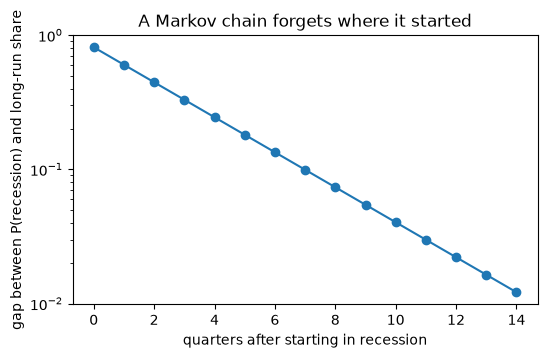

second eigenvalue: 0.741


In [12]:
dist = np.array([0.0, 1.0])
gaps = []
for n in range(15):
    gaps.append(abs(dist[1] - pi_star[1]))
    dist = dist @ P
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(gaps, "o-")
ax.set_xlabel("quarters after starting in recession")
ax.set_ylabel("gap between P(recession) and long-run share")
ax.set_title("A Markov chain forgets where it started")
plt.show()
print("second eigenvalue:", np.sort(np.real(w))[0].round(3))

## 6. A second chain: high or low unemployment

Define the state as **high** unemployment (6% or more) or **low**, using the same quarterly data. High unemployment is very persistent here, which changes the long-run answer.

In [13]:
st = (us["unemp"].to_numpy() >= 6.0).astype(int)
C = np.zeros((2, 2))
for now, nxt in zip(st[:-1], st[1:]):
    C[now, nxt] += 1
P2 = C / C.sum(axis=1, keepdims=True)
print("P2 =\n", P2.round(3))

# stationary distribution by solving (P' - I) pi = 0 with the extra equation sum(pi) = 1
M3 = np.vstack([P2.T - np.eye(2), np.ones(2)])
pi2 = np.linalg.lstsq(M3, np.array([0.0, 0.0, 1.0]), rcond=None)[0]
print("stationary distribution:", pi2.round(3), "  share of sample quarters in high-unemployment:", st.mean().round(3))
print("expected high-unemployment spell:", round(1 / (1 - P2[1, 1]), 1), "quarters")

P2 =
 [[0.944 0.056]
 [0.079 0.921]]
stationary distribution: [0.587 0.413]   share of sample quarters in high-unemployment: 0.379
expected high-unemployment spell: 12.7 quarters


The stationary share (about 41%) differs from the sample share (about 38%): the chain is estimated from transitions only, and the sample is a short, specific stretch of history. Always ask whether the "long run" of a model describes the data's own history or something the data did not live long enough to show.

## 7. In-class lab

The exercises for this week are in **Lab 7**, which doubles as a **practice run for the midterm**: it uses the same format (released and collected by script, paper part first, then the codespace). It appears in the `lab07` folder of your repository at the start of the second class session (pull to see it).

## This week

- Read *Python Programming for Economics and Finance*: [FC 17. Linear Equations and Matrix Algebra](https://intro.quantecon.org/linear_equations.html) and [FC 40. Markov Chains: Basic Concepts](https://intro.quantecon.org/markov_chains_I.html).
- **PS07** (linked markets, an input-output model, a Markov chain) is in the `ps07` folder of your repo.
- Next week: randomness and simulation, and the **midterm**.